# A/B test: sample size and power

**Question:** could Simple English Wikipedia run an A/B test of a friendly message sent to newcomers whose first-day
edit is reverted, and how long would it take?

The full design (hypothesis, groups, metrics, guardrails and risks) is in
[docs/ab_test_design.md](../../docs/ab_test_design.md). This notebook does the numbers behind it (decision 16):

- **Who is in the test:** newcomers with a first-day edit reverted by someone else (decisions 7 and 12).
- **Primary metric:** retained in the second month, at least one human edit in days 30–60 (decision 6).
- **Smallest effect worth detecting:** +1 percentage point.
- **Test settings:** two-sided, 5% significance level, 80% power, 50/50 split.
- **Baseline:** the cohorts 2021–2025, the five most recent full years.

Three terms are used throughout:

- **Significance level (5%):** the chance of a false alarm, declaring that the message works when it does nothing.
- **Power (80%):** the chance that the test detects a real effect of the chosen size. The other 20% of the time
  a real effect of that size is missed.
- **Minimum detectable effect (+1 point):** the smallest effect the test is built to detect with that power.

In [1]:
import math
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

DB_PATH = Path.cwd().parents[1] / "data" / "wiki.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)

# The test settings of decision 16
ALPHA = 0.05
POWER = 0.80
LIFT = 0.01          # +1 percentage point
RECENT_YEARS = (2021, 2025)


def query(sql):
    # Plain numeric types, ready for charts
    return con.sql(sql).df()


# Chart style: one hue per series, recessive grid and axes, text in neutral ink
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_MUTED, "xtick.color": TEXT_MUTED, "ytick.color": TEXT_MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 1. Who would be in the test, and the baseline

One row per newcomer of 2021–2025 who had a first-day edit reverted. The time of the first revert comes from
`raw_events`, which stores the seconds from each edit to the edit that reverted it. It tells us when the message
would be sent.

In [2]:
reverted = query(f"""
    with first_day_edits as (
        select
            n.user_id,
            n.cohort_year,
            n.retained_second_month::int as retained_second_month,
            n.retained_months_3_to_6::int as retained_main,
            -- hours from the newcomer's first edit to the revert of this edit
            (epoch(e.event_timestamp - n.first_edit_at) + r.revision_seconds_to_identity_revert) / 3600
                as hours_to_revert
        from newcomers n
        join edits e
          on e.editor_type = 'registered'
         and e.user_id = n.user_id
         and e.event_timestamp < n.first_edit_at + interval 1 day
         and e.is_reverted
        join raw_events r
          on r.event_entity = 'revision'
         and r.revision_id = e.revision_id
        where n.cohort_year between {RECENT_YEARS[0]} and {RECENT_YEARS[1]}
    )
    select user_id, cohort_year, retained_second_month, retained_main, min(hours_to_revert) as hours_to_first_revert
    from first_day_edits
    group by all
    -- a fixed row order: without it DuckDB can return the rows in any order, and the seeded
    -- random A/A splits in section 4 would then differ from run to run
    order by user_id
""")

baseline = reverted["retained_second_month"].mean()
per_year = len(reverted) / 5
print(f"reverted newcomers {RECENT_YEARS[0]}-{RECENT_YEARS[1]}: {len(reverted):,} ({per_year:,.0f} a year)")
print(f"retained in the second month: {baseline:.2%}; in months 3-6: {reverted['retained_main'].mean():.2%}")

by_year = reverted.groupby("cohort_year").agg(
    reverted_newcomers=("user_id", "count"),
    retained_second_month_pct=("retained_second_month", "mean"),
    retained_main_pct=("retained_main", "mean"),
)
by_year[["retained_second_month_pct", "retained_main_pct"]] *= 100
by_year.round(2)

reverted newcomers 2021-2025: 12,828 (2,566 a year)
retained in the second month: 2.78%; in months 3-6: 2.96%


,reverted_newcomers,retained_second_month_pct,retained_main_pct
cohort_year,,,
2021,2107,3.56,3.94
2022,2324,2.80,2.97
2023,2776,2.02,2.31
2024,2855,3.01,2.84
2025,2766,2.68,3.00


In [3]:
# The message is sent when the revert happens: how soon after the first edit is that?
hours = reverted["hours_to_first_revert"]
pd.Series({
    "within 10 minutes": (hours < 1 / 6).mean(),
    "within 1 hour": (hours < 1).mean(),
    "within 1 day": (hours < 24).mean(),
    "within 7 days": (hours < 24 * 7).mean(),
}).mul(100).round(1).rename("% of reverted newcomers").to_frame()

,% of reverted newcomers
within 10 minutes,49.8
within 1 hour,68.2
within 1 day,87.8
within 7 days,94.9


## 2. How many newcomers the test needs

The calculation turns the two retention rates (the baseline, and the baseline plus 1 point) into a standardized
difference, then finds the number of newcomers per group at which a test with these settings detects that
difference 80% of the time. Each group must be that large, so the test needs twice as many in all.

The test can't end when the last newcomer joins: the second-month window ends 60 days after their first edit, so the
result comes 2 months later.

In [4]:
def newcomers_per_group(baseline, lift, alpha=ALPHA, power=POWER):
    effect = proportion_effectsize(baseline + lift, baseline)
    n = NormalIndPower().solve_power(effect_size=effect, alpha=alpha, power=power, ratio=1, alternative="two-sided")
    # Rounded up: rounding down would leave the test just short of the planned power
    return math.ceil(n)


def months_to_result(per_group, follow_up_months=2):
    enrolment_months = 2 * per_group / (per_year / 12)
    return enrolment_months + follow_up_months


rows = []
for lift_pp in (0.5, 1.0, 1.5, 2.0):
    n = newcomers_per_group(baseline, lift_pp / 100)
    rows.append({"lift_pp": lift_pp, "relative_lift_pct": 100 * lift_pp / 100 / baseline,
                 "per_group": n, "total": 2 * n, "months_to_result": months_to_result(n)})
sample_sizes = pd.DataFrame(rows).set_index("lift_pp")
sample_sizes.round(0).astype(int)

,relative_lift_pct,per_group,total,months_to_result
lift_pp,,,,
0.5,18,18390,36780,174
1.0,36,4945,9890,48
1.5,54,2347,4694,24
2.0,72,1401,2802,15


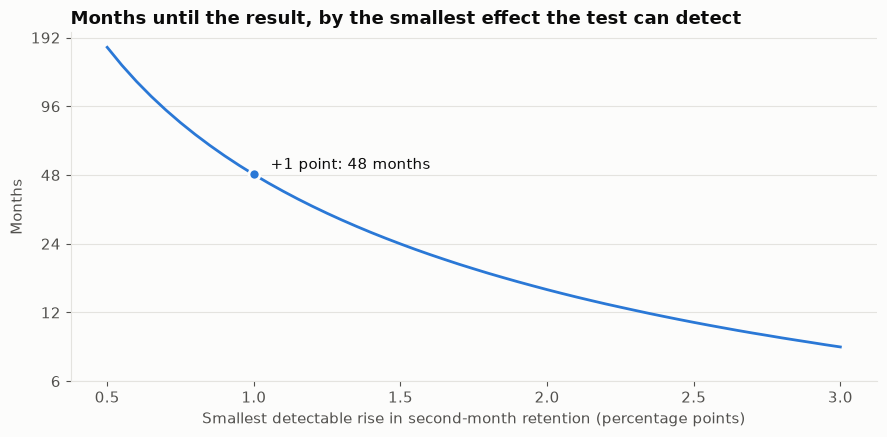

In [5]:
lifts = np.linspace(0.5, 3.0, 51)
months = [months_to_result(newcomers_per_group(baseline, lift / 100)) for lift in lifts]
chosen_n = newcomers_per_group(baseline, LIFT)
chosen_months = months_to_result(chosen_n)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(lifts, months, color=BLUE, linewidth=2)
ax.plot([LIFT * 100], [chosen_months], "o", color=BLUE, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
ax.annotate(f"+1 point: {chosen_months:.0f} months", (LIFT * 100, chosen_months), xytext=(12, 4),
            textcoords="offset points", color=TEXT)
ax.set_title("Months until the result, by the smallest effect the test can detect")
ax.set_xlabel("Smallest detectable rise in second-month retention (percentage points)")
ax.set_ylabel("Months")
ax.set_yscale("log")
ax.set_yticks([6, 12, 24, 48, 96, 192])
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0f}")
ax.yaxis.set_minor_locator(plt.NullLocator())
plt.tight_layout()
plt.show()

## 3. What 5% significance and 80% power mean, by simulation

A simulation makes the two settings visible. It runs 2,000 imaginary experiments of the planned size (4,945
newcomers per group), each time drawing who is retained at random, and tests each one:

- **No real effect:** both groups are retained at the baseline rate. Any "significant" result is a false alarm,
  and they should happen about 5% of the time.
- **A real effect of +1 point:** the treatment group is retained at the baseline plus 1 point. The test should
  detect it about 80% of the time.

In [6]:
rng = np.random.default_rng(16)   # a fixed seed, so the notebook gives the same numbers every run
n = chosen_n
experiments = 2_000


def simulate(treatment_rate):
    control = rng.binomial(n, baseline, size=experiments)
    treatment = rng.binomial(n, treatment_rate, size=experiments)
    p_values = np.array([proportions_ztest([t, c], [n, n])[1] for t, c in zip(treatment, control)])
    return (treatment - control) / n, p_values


diff_none, p_none = simulate(baseline)
diff_real, p_real = simulate(baseline + LIFT)
print(f"no real effect:    {np.mean(p_none < ALPHA):.1%} of experiments 'significant' (false alarms)")
print(f"+1 point effect:   {np.mean(p_real < ALPHA):.1%} of experiments significant (power)")

no real effect:    4.5% of experiments 'significant' (false alarms)
+1 point effect:   78.8% of experiments significant (power)


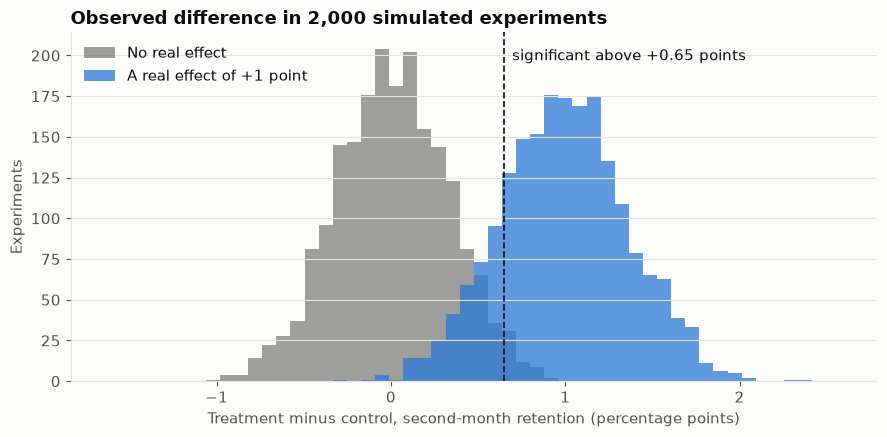

In [7]:
# The difference a single experiment must show to be significant, at the baseline rate
threshold = 1.96 * np.sqrt(2 * baseline * (1 - baseline) / n)

fig, ax = plt.subplots(figsize=(9, 4.5))
# A difference can only move in steps of one newcomer (1/n), so each bar covers exactly 4 steps
bins = (np.arange(-80, 132, 4) - 0.5) / n * 100
ax.hist(diff_none * 100, bins=bins, color=TEXT_MUTED, alpha=0.55, label="No real effect")
ax.hist(diff_real * 100, bins=bins, color=BLUE, alpha=0.75, label="A real effect of +1 point")
ax.axvline(threshold * 100, color=TEXT, linewidth=1.2, linestyle="--")
ax.annotate(f"significant above +{threshold * 100:.2f} points", (threshold * 100, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=TEXT)
ax.set_title("Observed difference in 2,000 simulated experiments")
ax.set_xlabel("Treatment minus control, second-month retention (percentage points)")
ax.set_ylabel("Experiments")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## 4. A check on real newcomers: an A/A test

The simulation assumes each newcomer stays or leaves independently of the others. An **A/A test** checks that on
real data: it splits the real reverted newcomers of 2021–2025 into two random halves, where neither half got
anything different, and tests the difference. Repeated 1,000 times, about 5% of the splits should look significant.

In [8]:
outcomes = reverted["retained_second_month"].to_numpy()
half = len(outcomes) // 2
aa_p_values = []
for _ in range(1_000):
    shuffled = rng.permutation(outcomes)
    a, b = shuffled[:half], shuffled[half:2 * half]
    aa_p_values.append(proportions_ztest([a.sum(), b.sum()], [half, half])[1])
print(f"A/A splits of {half:,} vs {half:,}: {np.mean(np.array(aa_p_values) < ALPHA):.1%} 'significant'")

A/A splits of 6,414 vs 6,414: 4.9% 'significant'


## 5. Can the test be shortened?

Not by much on this wiki alone:

- **Adjusting for what is known before the message** (creation method, first edit in an article, started on mobile,
  edits made before the revert) makes the estimate more precise, which works like a larger sample. But these explain
  only 2.2% of the variation in second-month retention (`analysis/profiling/profile_ab_test.py`), so the test would need just
  2.2% fewer newcomers.
- **Running the same test on several wikis at once** shortens it in proportion to how many reverted newcomers they
  have together. The table shows the time to the result if the wikis together had 2, 5 or 10 times as many reverted
  newcomers as Simple English Wikipedia. Their real numbers would come from their own dumps.

In [9]:
pd.DataFrame({
    "reverted_newcomers_per_month": [per_year / 12 * k for k in (1, 2, 5, 10)],
    "months_to_result": [2 * chosen_n / (per_year / 12 * k) + 2 for k in (1, 2, 5, 10)],
}, index=pd.Index(["Simple English only", "2 times as many", "5 times as many", "10 times as many"],
                  name="wikis in the test")).round(0).astype(int)

,reverted_newcomers_per_month,months_to_result
wikis in the test,,
Simple English only,214,48
2 times as many,428,25
5 times as many,1069,11
10 times as many,2138,7


## Findings

**1. The test would reach newcomers at the right moment, but there are few of them.** In 2021–2025, 2,566
newcomers a year (12,828 in all) had a first-day edit reverted. About half of the first reverts came within 10 minutes of
the newcomer's first edit, 68.2% within an hour and 87.8% within a day, so a message sent at the revert would reach
most of them while they were still on the site. 2.78% of them were retained in the second month, between 2.02% and
3.56% depending on the year.

**2. Detecting a rise of 1 percentage point would take about 4 years.** To detect a rise from 2.78% to 3.78% (36% in
relative terms) with a 5% significance level and 80% power, the test needs 4,945 newcomers in each group, 9,890 in
all. At 214 reverted newcomers a month, that is 46 months of enrolment, plus 2 months until the last newcomer's
second month is over: 48 months. The time grows fast as the effect gets smaller: 15 months for +2 points,
174 months for +0.5.

**3. The simulation shows what the settings mean.** In 2,000 simulated experiments of the planned size where the
message does nothing, 4.5% looked significant: false alarms. Where the message adds 1 point, 78.8% were significant;
the rest missed a real effect. Both are close to the 5% and 80% the test was designed for (with 2,000 experiments
they can differ by about a point by chance). Splitting the real reverted newcomers into two random halves 1,000
times gave 4.9% significant results, so the calculation holds on real data.

**4. The test can only be shortened much by running it on more wikis.** Adjusting for what is known before the
message would reduce the sample needed by only 2.2%. Wikis with 5 times as many reverted newcomers in total would get
the result in 11 months, and 10 times as many in 7.

**What this means:** on Simple English Wikipedia alone, the test is possible but slow. A product team should run it
on several wikis at once, or accept that it can only detect a large effect. The design is in
[docs/ab_test_design.md](../../docs/ab_test_design.md).